This is the documentation from Matplotlib for Nested Pie Charts

In [3]:
import matplotlib.pyplot as plt
import numpy as np

The most straightforward way to build a pie chart is to use the pie method.

In this case, pie takes values corresponding to counts in a group. We'll first generate some fake data, corresponding to three groups. In the inner circle, we'll treat each number as belonging to its own group. In the outer circle, we'll plot them as members of their original 3 groups.

The effect of the donut shape is achieved by setting a width to the pie's wedges through the wedgeprops argument.

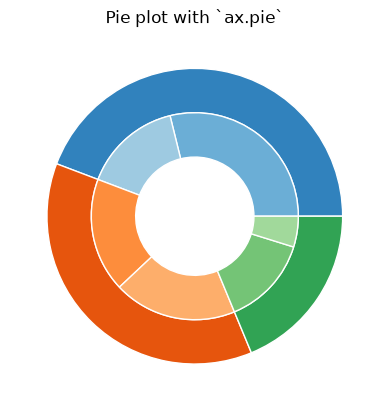

In [2]:
fig, ax = plt.subplots()

size = 0.3
vals = np.array([[60., 32.], [37., 40.], [29., 10.]])

tab20c = plt.color_sequences["tab20c"]
outer_colors = [tab20c[i] for i in [0, 4, 8]]
inner_colors = [tab20c[i] for i in [1, 2, 5, 6, 9, 10]]

ax.pie(vals.sum(axis=1), radius=1, colors=outer_colors,
       wedgeprops=dict(width=size, edgecolor='w'))

ax.pie(vals.flatten(), radius=1-size, colors=inner_colors,
       wedgeprops=dict(width=size, edgecolor='w'))

ax.set(aspect="equal", title='Pie plot with `ax.pie`')
plt.show()

However, you can accomplish the same output by using a bar plot on Axes with a polar coordinate system. This may give more flexibility on the exact design of the plot.

In this case, we need to map x-values of the bar chart onto radians of a circle. The cumulative sum of the values are used as the edges of the bars.

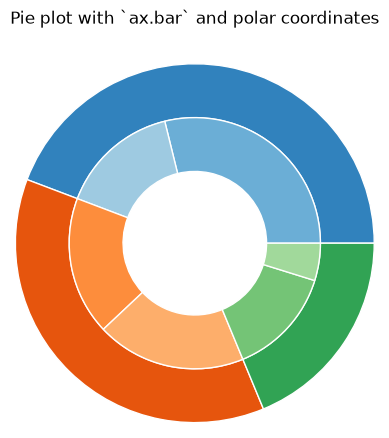

In [3]:
fig, ax = plt.subplots(subplot_kw=dict(projection="polar"))

size = 0.3
vals = np.array([[60., 32.], [37., 40.], [29., 10.]])
# Normalize vals to 2 pi
valsnorm = vals/np.sum(vals)*2*np.pi
# Obtain the ordinates of the bar edges
valsleft = np.cumsum(np.append(0, valsnorm.flatten()[:-1])).reshape(vals.shape)

cmap = plt.colormaps["tab20c"]
outer_colors = cmap(np.arange(3)*4)
inner_colors = cmap([1, 2, 5, 6, 9, 10])

ax.bar(x=valsleft[:, 0],
       width=valsnorm.sum(axis=1), bottom=1-size, height=size,
       color=outer_colors, edgecolor='w', linewidth=1, align="edge")

ax.bar(x=valsleft.flatten(),
       width=valsnorm.flatten(), bottom=1-2*size, height=size,
       color=inner_colors, edgecolor='w', linewidth=1, align="edge")

ax.set(title="Pie plot with `ax.bar` and polar coordinates")
ax.set_axis_off()
plt.show()

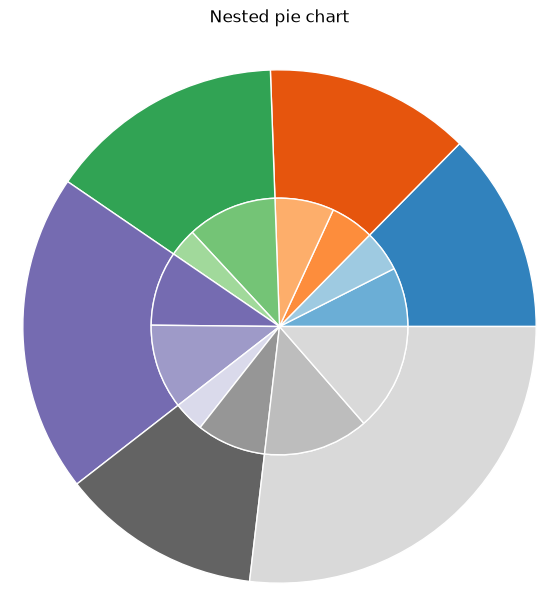

In [1]:
from matplotlib import pyplot as plt
import numpy as np

size = 6
cars = ['AUDI', 'BMW', 'FORD', 'TESLA', 'JAGUAR', 'MERCEDES']
data = np.array([[23, 16], [17, 23],
                 [35, 11], [29, 33],
                 [12, 27], [41, 42]])

norm = data / np.sum(data)*2 * np.pi
left = np.cumsum(np.append(0, norm.flatten()[:-1])).reshape(data.shape)
cmap = plt.get_cmap("tab20c")
outer_colors = cmap(np.arange(6)*4)
inner_colors = cmap(np.array([1, 2, 5, 6, 9,
                              10, 12, 13, 15,
                              17, 18, 20]))

fig, ax = plt.subplots(figsize=(10, 7), subplot_kw=dict(polar=True))
ax.bar(x=left[:, 0],
       width=norm.sum(axis=1),
       bottom=1-size,
       height=size,
       color=outer_colors,
       edgecolor='w',
       linewidth=1,
       align="edge")

ax.bar(x=left.flatten(),
       width=norm.flatten(),
       bottom=1-2 * size,
       height=size,
       color=inner_colors,
       edgecolor='w',
       linewidth=1,
       align="edge")

ax.set(title="Nested pie chart")
ax.set_axis_off()
plt.show()

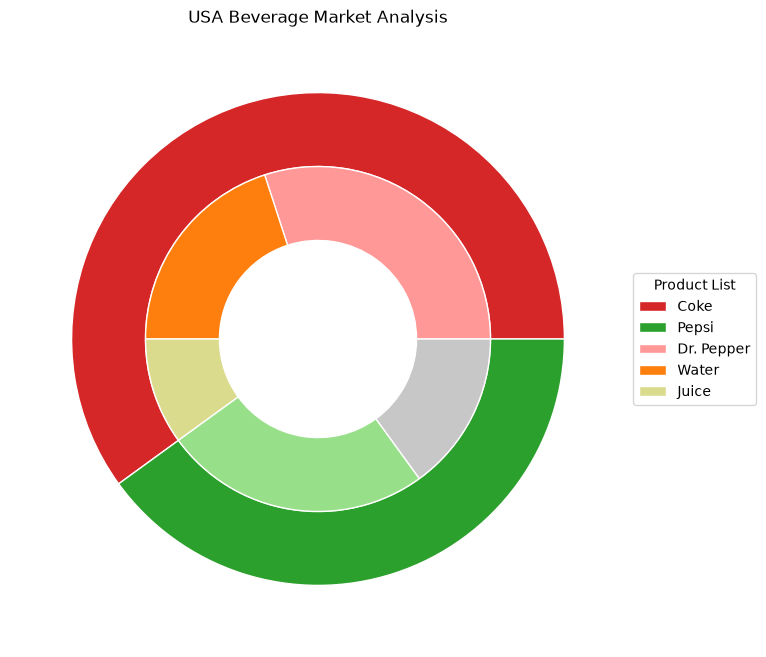

In [1]:
import matplotlib.pyplot as plt

# Data
categories = ['Soda', 'Healthy']
cat_totals = [60, 40]

sub_categories = ['Coke', 'Pepsi', 'Dr. Pepper', 'Water', 'Juice']
sub_totals = [30, 20, 10, 25, 15]

fig, ax = plt.subplots(figsize=(8, 8))

# Outer Chart
outer = ax.pie(cat_totals, radius=1, colors=['#d62728', '#2ca02c'],
               wedgeprops=dict(width=0.3, edgecolor='w'))

# Inner Chart
inner = ax.pie(sub_totals, radius=0.7, colors=['#ff9896', '#ff7f0e', '#dbdb8d', '#98df8a', '#c7c7c7'],
               wedgeprops=dict(width=0.3, edgecolor='w'))

# Adding a Legend
ax.legend(sub_categories, title="Product List", loc="center left", bbox_to_anchor=(1, 0, 0.5, 1))

plt.title("USA Beverage Market Analysis")
plt.show()

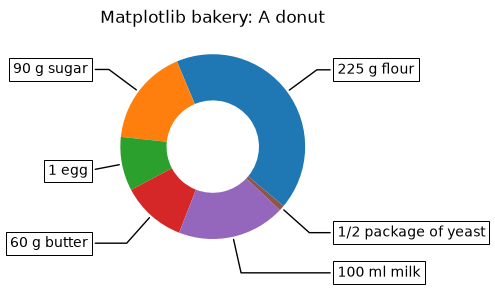

In [4]:
fig, ax = plt.subplots(figsize=(6, 3), subplot_kw=dict(aspect="equal"))

recipe = ["225 g flour",
          "90 g sugar",
          "1 egg",
          "60 g butter",
          "100 ml milk",
          "1/2 package of yeast"]

data = [225, 90, 50, 60, 100, 5]

pie = ax.pie(data, wedgeprops=dict(width=0.5), startangle=-40)

bbox_props = dict(boxstyle="square,pad=0.3", fc="w", ec="k", lw=0.72)
kw = dict(arrowprops=dict(arrowstyle="-"),
          bbox=bbox_props, zorder=0, va="center")

for i, p in enumerate(pie.wedges):
    ang = (p.theta2 - p.theta1)/2. + p.theta1
    y = np.sin(np.deg2rad(ang))
    x = np.cos(np.deg2rad(ang))
    horizontalalignment = {-1: "right", 1: "left"}[int(np.sign(x))]
    connectionstyle = f"angle,angleA=0,angleB={ang}"
    kw["arrowprops"].update({"connectionstyle": connectionstyle})
    ax.annotate(recipe[i], xy=(x, y), xytext=(1.35*np.sign(x), 1.4*y),
                horizontalalignment=horizontalalignment, **kw)

ax.set_title("Matplotlib bakery: A donut")

plt.show()